# Flight Fare Prediction Using Machine Learning

## 1. Problem Statement

Flight ticket prices are often unpredictable and can change depending on various factors such as airline, journey date, source, destination, departure time, arrival time, duration, and number of stops.

The objective of this project is to analyze historical flight fare data and develop machine learning models that can predict the price of a flight based on its travel-related features.

## 2. Objectives

* Perform exploratory data analysis (EDA) on the flight fare dataset.
* Understand the factors that influence flight ticket prices.
* Clean and preprocess the dataset for machine learning.
* Perform feature engineering on date, time, duration, and categorical variables.
* Build multiple machine learning regression models.
* Evaluate and compare the performance of the models using suitable evaluation metrics.
* Identify a suitable model for production based on the evaluation results.
* Predict flight prices for new flight details.
* Document the challenges faced during data preprocessing and model development and explain the techniques used to address them.

## 3. Target Variable

The target variable for this project is **Price**.

The machine learning models will learn from historical flight information and use these features to predict the expected price of a flight.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
import os

os.listdir("Downloads")

['Anaconda3-2026.07-1-Windows-x86_64.exe',
 'desktop.ini',
 'flight-fare',
 'flight-fare.zip',
 'PRCP-1025-FlightPricePrediction.docx']

In [3]:
os.listdir("Downloads/flight-fare")

['Flight_Fare.xlsx']

In [4]:
file_path = "Downloads/flight-fare/Flight_Fare.xlsx"

df = pd.read_excel(file_path)

df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [5]:
df.shape

(10683, 11)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB


In [7]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [9]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [10]:
df[df.isnull().any(axis=1)]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [11]:
df.duplicated().sum()

np.int64(220)

In [12]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (10463, 11)


In [13]:
df = df.dropna()

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (10462, 11)


In [14]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["Airline"].value_counts()

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

In [17]:
df["Source"].value_counts()

Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64

In [18]:
df["Destination"].value_counts()

Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

In [19]:
df["Total_Stops"].value_counts()

Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
4 stops        1
Name: count, dtype: int64

In [20]:
df["Additional_Info"].value_counts()

Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [21]:
df["Date_of_Journey"].head(10)

0    24/03/2019
1     1/05/2019
2     9/06/2019
3    12/05/2019
4    01/03/2019
5    24/06/2019
6    12/03/2019
7    01/03/2019
8    12/03/2019
9    27/05/2019
Name: Date_of_Journey, dtype: str

In [22]:
df["Dep_Time"].head(10)

0    22:20
1    05:50
2    09:25
3    18:05
4    16:50
5    09:00
6    18:55
7    08:00
8    08:55
9    11:25
Name: Dep_Time, dtype: str

In [23]:
df["Arrival_Time"].head(10)

0    01:10 22 Mar
1           13:15
2    04:25 10 Jun
3           23:30
4           21:35
5           11:25
6    10:25 13 Mar
7    05:05 02 Mar
8    10:25 13 Mar
9           19:15
Name: Arrival_Time, dtype: str

In [24]:
df["Duration"].head(10)

0     2h 50m
1     7h 25m
2        19h
3     5h 25m
4     4h 45m
5     2h 25m
6    15h 30m
7     21h 5m
8    25h 30m
9     7h 50m
Name: Duration, dtype: str

In [25]:
df["Route"].head(10)

0                BLR → DEL
1    CCU → IXR → BBI → BLR
2    DEL → LKO → BOM → COK
3          CCU → NAG → BLR
4          BLR → NAG → DEL
5                CCU → BLR
6          BLR → BOM → DEL
7          BLR → BOM → DEL
8          BLR → BOM → DEL
9          DEL → BOM → COK
Name: Route, dtype: str

In [26]:
df["Price"].head(10)

0     3897
1     7662
2    13882
3     6218
4    13302
5     3873
6    11087
7    22270
8    11087
9     8625
Name: Price, dtype: int64

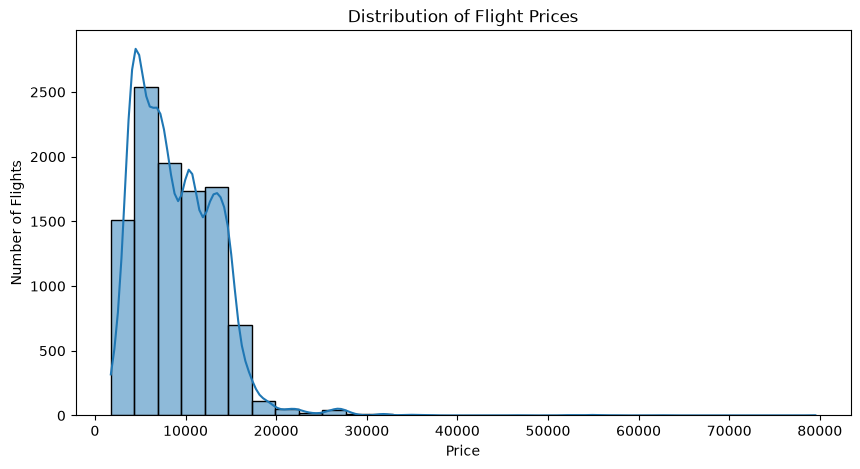

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Price"], bins=30, kde=True)

plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Number of Flights")

plt.show()

In [28]:
airline_price = df.groupby("Airline")["Price"].mean().sort_values(ascending=False)

print(airline_price)

Airline
Jet Airways Business                 58358.666667
Jet Airways                          11599.021081
Multiple carriers Premium economy    11418.846154
Multiple carriers                    10902.678094
Air India                             9556.608028
Vistara Premium economy               8962.333333
Vistara                               7801.355649
GoAir                                 5861.056701
IndiGo                                5668.469897
Air Asia                              5590.260188
SpiceJet                              4335.841718
Trujet                                4140.000000
Name: Price, dtype: float64


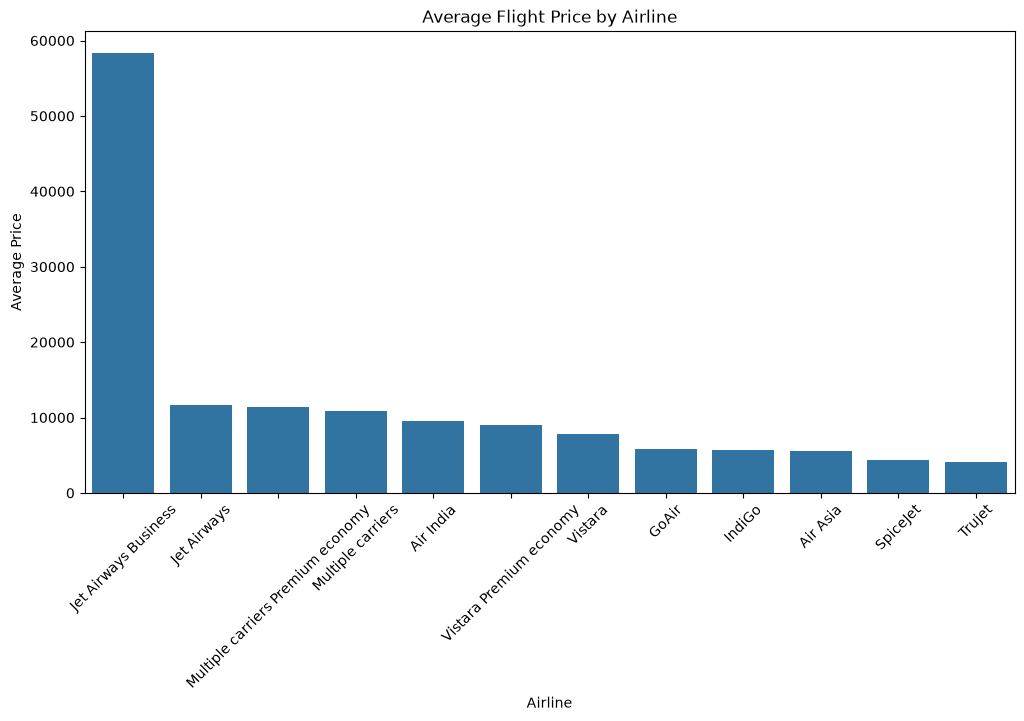

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=airline_price.index,
    y=airline_price.values
)

plt.title("Average Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price")

plt.xticks(rotation=45)
plt.show()

In [30]:
source_price = df.groupby("Source")["Price"].mean().sort_values(ascending=False)

print(source_price)

Source
Delhi       10461.600690
Kolkata      9143.083566
Banglore     8022.872877
Mumbai       5059.708752
Chennai      4789.892388
Name: Price, dtype: float64


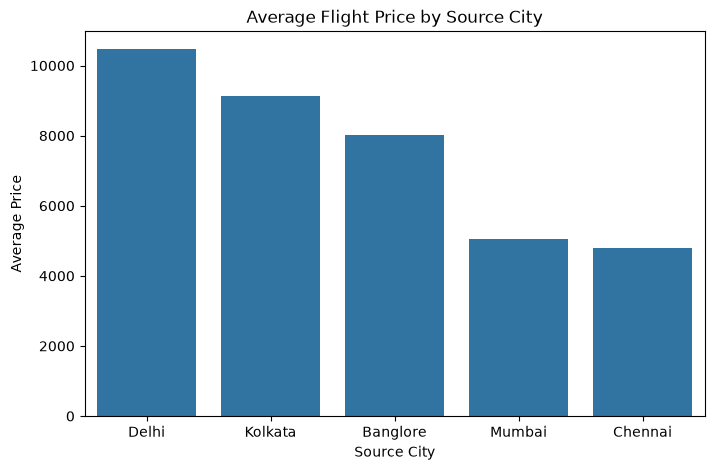

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=source_price.index,
    y=source_price.values
)

plt.title("Average Flight Price by Source City")
plt.xlabel("Source City")
plt.ylabel("Average Price")

plt.show()

In [32]:
stops_price = df.groupby("Total_Stops")["Price"].mean().sort_values(ascending=False)

print(stops_price)


Total_Stops
4 stops     17686.000000
3 stops     13260.674419
2 stops     12761.099393
1 stop      10594.123556
non-stop     5018.506763
Name: Price, dtype: float64


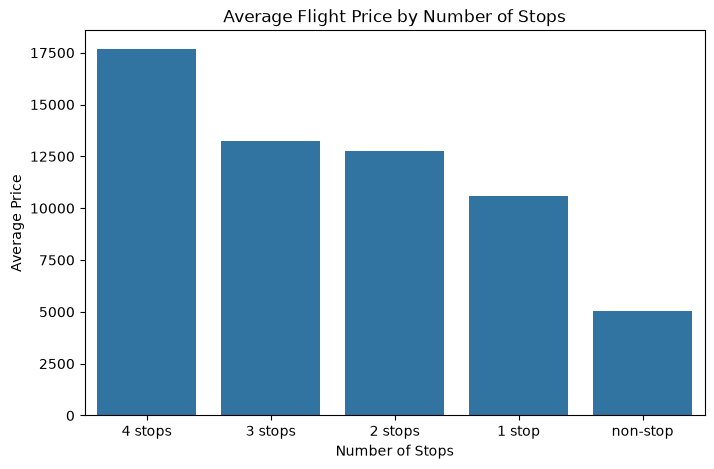

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=stops_price.index,
    y=stops_price.values
)

plt.title("Average Flight Price by Number of Stops")
plt.xlabel("Number of Stops")
plt.ylabel("Average Price")

plt.show()

In [34]:
destination_price = df.groupby("Destination")["Price"].mean().sort_values(ascending=False)

print(destination_price)

Destination
New Delhi    12007.421225
Cochin       10461.600690
Banglore      9143.083566
Delhi         5143.918577
Hyderabad     5059.708752
Kolkata       4789.892388
Name: Price, dtype: float64


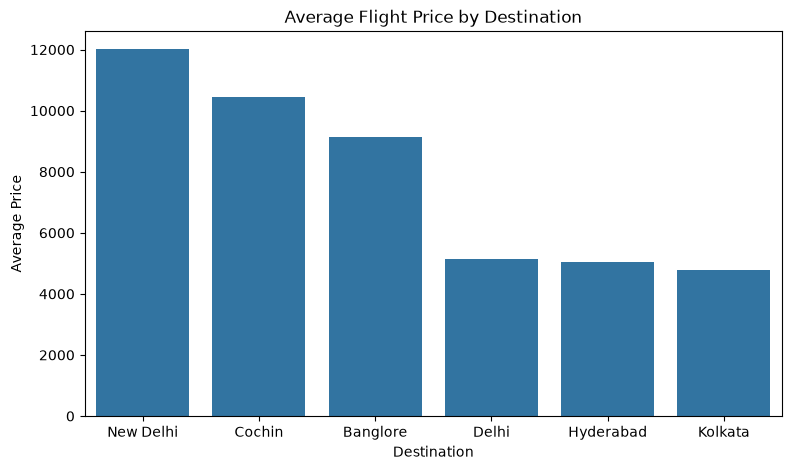

In [35]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=destination_price.index,
    y=destination_price.values
)

plt.title("Average Flight Price by Destination")
plt.xlabel("Destination")
plt.ylabel("Average Price")

plt.show()

In [36]:
def duration_to_minutes(duration):
    parts = duration.split()
    
    hours = 0
    minutes = 0
    
    for part in parts:
        if "h" in part:
            hours = int(part.replace("h", ""))
        elif "m" in part:
            minutes = int(part.replace("m", ""))
    
    return hours * 60 + minutes

In [37]:
print(duration_to_minutes("2h 50m"))
print(duration_to_minutes("7h 25m"))
print(duration_to_minutes("19h"))
print(duration_to_minutes("25h 30m"))

170
445
1140
1530


In [38]:
df["Duration_Minutes"] = df["Duration"].apply(duration_to_minutes)

df[["Duration", "Duration_Minutes"]].head(10)

,Duration,Duration_Minutes
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285
5,2h 25m,145
6,15h 30m,930
7,21h 5m,1265
8,25h 30m,1530
9,7h 50m,470


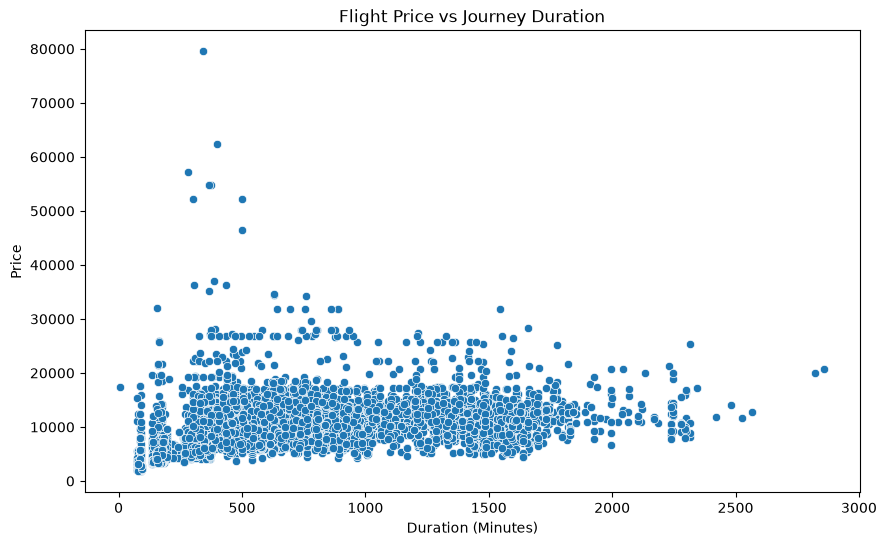

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df["Duration_Minutes"],
    y=df["Price"]
)

plt.title("Flight Price vs Journey Duration")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Price")

plt.show()

In [40]:
df["Journey_Month"] = df["Date_of_Journey"].str.split("/").str[1].astype(int)

df[["Date_of_Journey", "Journey_Month"]].head(10)

,Date_of_Journey,Journey_Month
0,24/03/2019,3
1,1/05/2019,5
2,9/06/2019,6
3,12/05/2019,5
4,01/03/2019,3
5,24/06/2019,6
6,12/03/2019,3
7,01/03/2019,3
8,12/03/2019,3
9,27/05/2019,5


In [41]:
month_price = df.groupby("Journey_Month")["Price"].mean()

print(month_price)

Journey_Month
3    10695.397311
4     5766.545455
5     9029.239764
6     8736.152522
Name: Price, dtype: float64


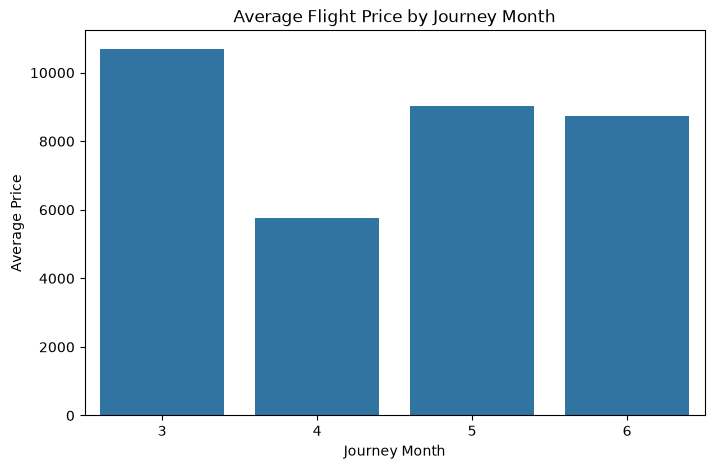

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(x=month_price.index, y=month_price.values)

plt.title("Average Flight Price by Journey Month")
plt.xlabel("Journey Month")
plt.ylabel("Average Price")

plt.show()

In [43]:
df["Dep_Hour"] = df["Dep_Time"].str.split(":").str[0].astype(int)

df[["Dep_Time", "Dep_Hour"]].head(10)

,Dep_Time,Dep_Hour
0,22:20,22
1,05:50,5
2,09:25,9
3,18:05,18
4,16:50,16
5,09:00,9
6,18:55,18
7,08:00,8
8,08:55,8
9,11:25,11


In [44]:
hour_price = df.groupby("Dep_Hour")["Price"].mean()

print(hour_price)

Dep_Hour
0      7615.075000
1      4354.621622
2      8419.974227
3     10474.625000
4      7266.520710
5      9480.309278
6      8252.195556
7      8485.902665
8     10073.923631
9      9559.092551
10     8870.728653
11     9296.739206
12     9251.573034
13     8998.725061
14     9816.409901
15     7687.410658
16    10330.783080
17     8710.355588
18    10043.981859
19     8344.700368
20     9683.838213
21     8450.296524
22     7765.975871
23     8487.338346
Name: Price, dtype: float64


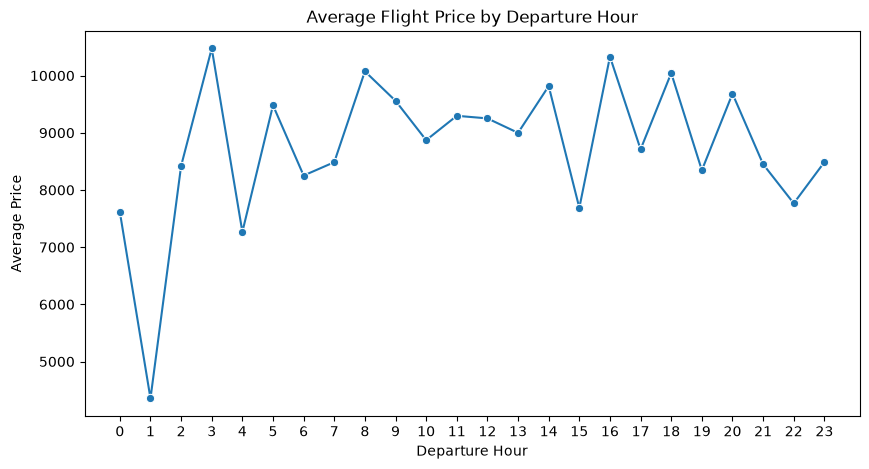

In [45]:
plt.figure(figsize=(10, 5))

sns.lineplot(x=hour_price.index, y=hour_price.values, marker="o")

plt.title("Average Flight Price by Departure Hour")
plt.xlabel("Departure Hour")
plt.ylabel("Average Price")
plt.xticks(range(24))

plt.show()

In [46]:
df["Arrival_Hour"] = df["Arrival_Time"].str.split(":").str[0].astype(int)

df[["Arrival_Time", "Arrival_Hour"]].head(10)

,Arrival_Time,Arrival_Hour
0,01:10 22 Mar,1
1,13:15,13
2,04:25 10 Jun,4
3,23:30,23
4,21:35,21
5,11:25,11
6,10:25 13 Mar,10
7,05:05 02 Mar,5
8,10:25 13 Mar,10
9,19:15,19


In [47]:
arrival_price = df.groupby("Arrival_Hour")["Price"].mean()

print(arrival_price)

Arrival_Hour
0      5642.447205
1      9636.845714
2      5151.886076
3      4934.638298
4     11355.286465
5     15532.151515
6      5819.470588
7      7796.538647
8      8051.175214
9      9203.018405
10     8118.831224
11     7417.629630
12     9560.559814
13     7499.521452
14     6627.581633
15     8925.412088
16     9272.121622
17     5820.633508
18    10612.119843
19    10936.235521
20     8267.570292
21     8676.784593
22     7575.583591
23     8947.058212
Name: Price, dtype: float64


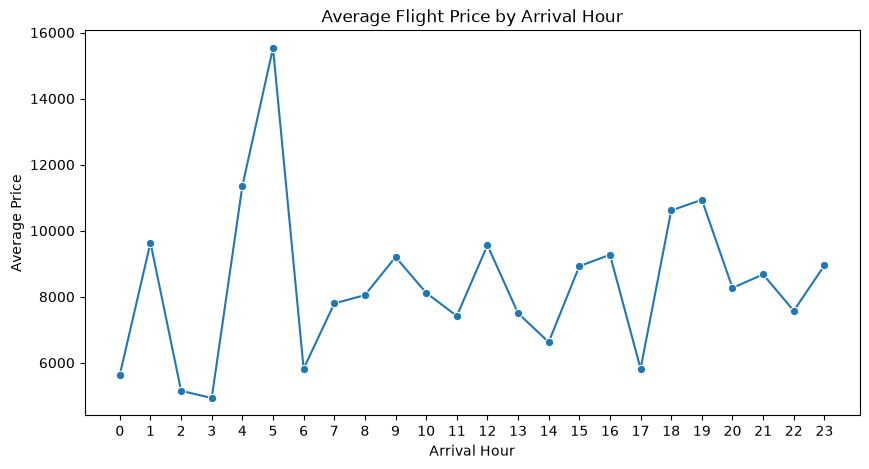

In [48]:
plt.figure(figsize=(10, 5))

sns.lineplot(x=arrival_price.index, y=arrival_price.values, marker="o")

plt.title("Average Flight Price by Arrival Hour")
plt.xlabel("Arrival Hour")
plt.ylabel("Average Price")
plt.xticks(range(24))

plt.show()

In [49]:
dep_hour_counts = df["Dep_Hour"].value_counts().sort_index()

print(dep_hour_counts)

Dep_Hour
0      40
1      37
2     194
3      24
4     169
5     582
6     675
7     863
8     694
9     886
10    527
11    579
12    178
13    411
14    505
15    319
16    461
17    689
18    441
19    544
20    649
21    489
22    373
23    133
Name: count, dtype: int64


In [50]:
arrival_hour_counts = df["Arrival_Hour"].value_counts().sort_index()

print(arrival_hour_counts)

Arrival_Hour
0      322
1      525
2       79
3       47
4      761
5       66
6       51
7      414
8      468
9      489
10     474
11     297
12     861
13     303
14     294
15     182
16     370
17     191
18     509
19    1554
20     377
21     701
22     646
23     481
Name: count, dtype: int64


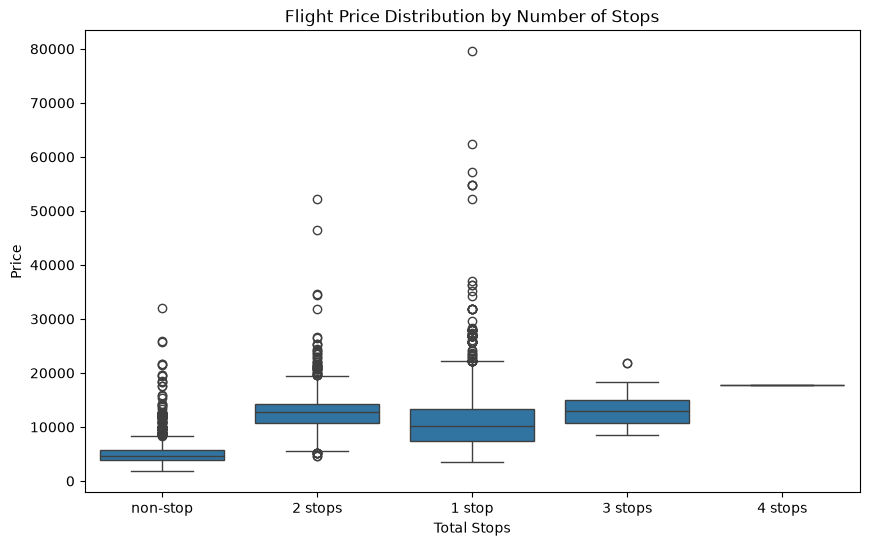

In [51]:
plt.figure(figsize=(10, 6))

sns.boxplot(x="Total_Stops", y="Price", data=df)

plt.title("Flight Price Distribution by Number of Stops")
plt.xlabel("Total Stops")
plt.ylabel("Price")

plt.show()

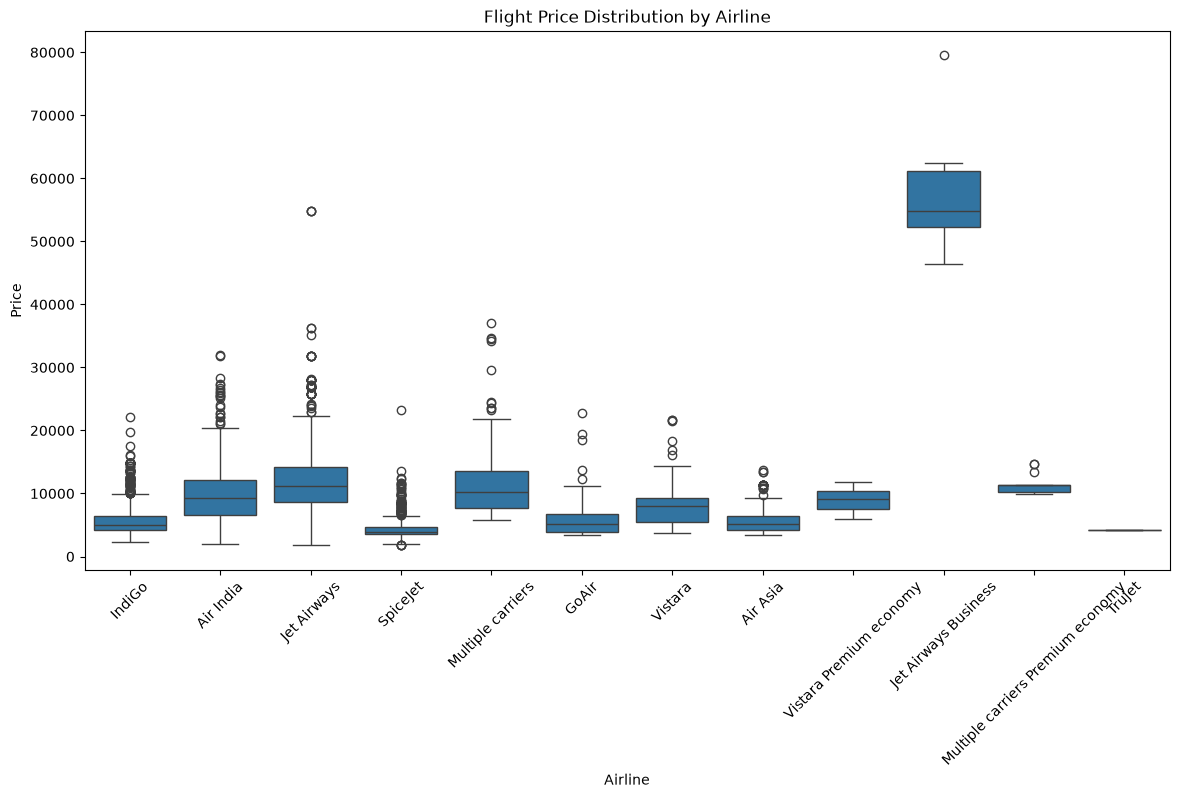

In [52]:
plt.figure(figsize=(14, 7))

sns.boxplot(x="Airline", y="Price", data=df)

plt.title("Flight Price Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Price")
plt.xticks(rotation=45)

plt.show()

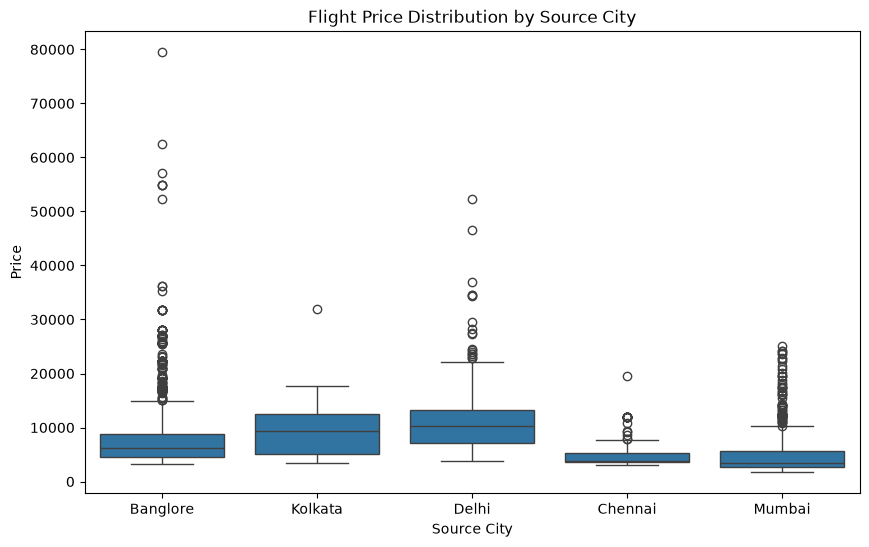

In [53]:
plt.figure(figsize=(10, 6))

sns.boxplot(x="Source", y="Price", data=df)

plt.title("Flight Price Distribution by Source City")
plt.xlabel("Source City")
plt.ylabel("Price")

plt.show()

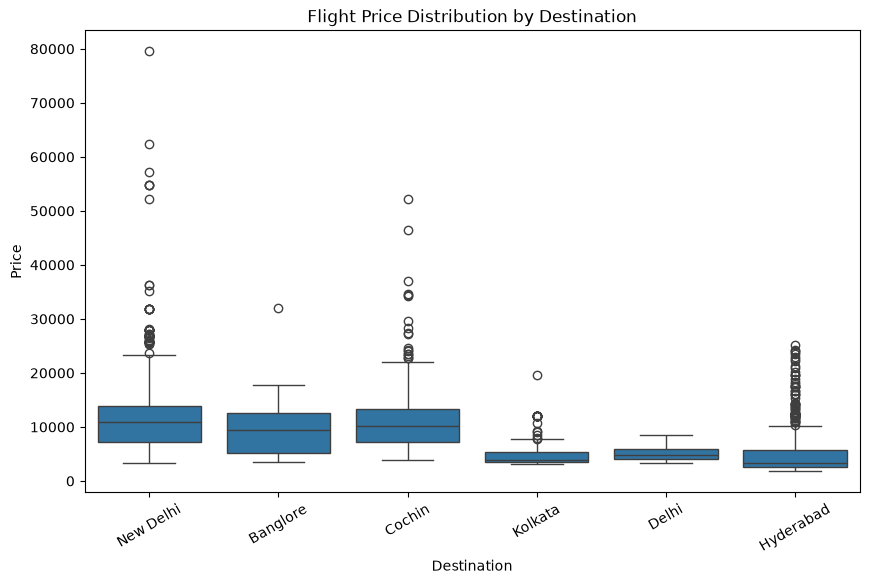

In [54]:
plt.figure(figsize=(10, 6))

sns.boxplot(x="Destination", y="Price", data=df)

plt.title("Flight Price Distribution by Destination")
plt.xlabel("Destination")
plt.ylabel("Price")

plt.xticks(rotation=30)

plt.show()

In [55]:
df.select_dtypes(include=["int64", "float64"]).columns

Index(['Price', 'Duration_Minutes', 'Journey_Month', 'Dep_Hour',
       'Arrival_Hour'],
      dtype='str')

In [56]:
correlation = df[["Price", "Duration_Minutes", "Journey_Month", "Dep_Hour", "Arrival_Hour"]].corr()

print(correlation)

                     Price  Duration_Minutes  Journey_Month  Dep_Hour  \
Price             1.000000          0.501758      -0.113396  0.005155   
Duration_Minutes  0.501758          1.000000       0.004874 -0.001285   
Journey_Month    -0.113396          0.004874       1.000000  0.040406   
Dep_Hour          0.005155         -0.001285       0.040406  1.000000   
Arrival_Hour      0.031023          0.061912       0.001423 -0.003827   

                  Arrival_Hour  
Price                 0.031023  
Duration_Minutes      0.061912  
Journey_Month         0.001423  
Dep_Hour             -0.003827  
Arrival_Hour          1.000000  


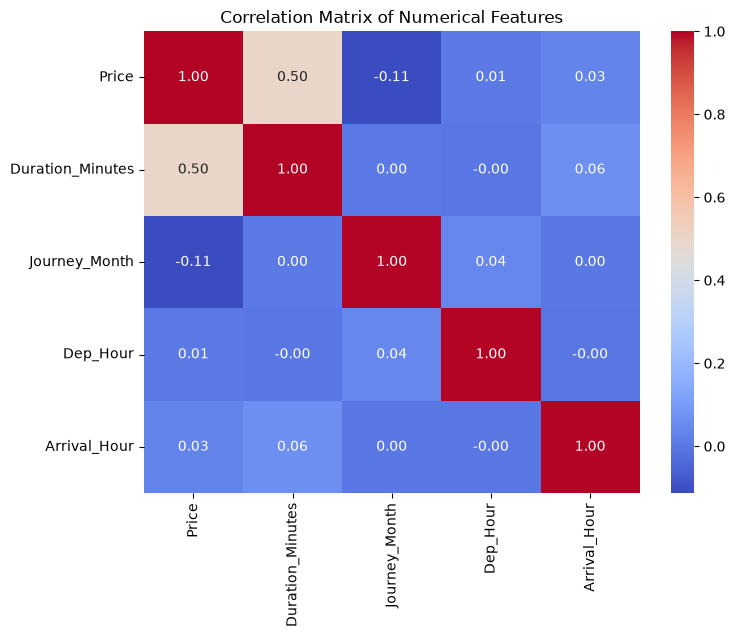

In [57]:
plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix of Numerical Features")

plt.show()

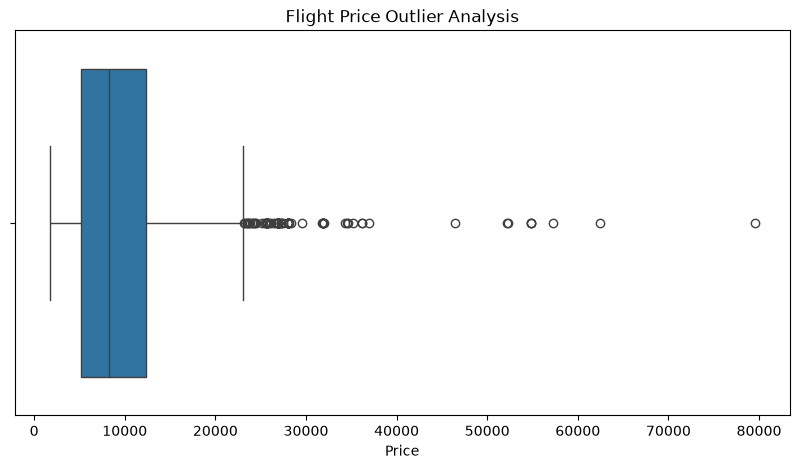

In [58]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Price"])

plt.title("Flight Price Outlier Analysis")
plt.xlabel("Price")

plt.show()

In [59]:
df[["Duration_Minutes", "Journey_Month", "Dep_Hour", "Arrival_Hour", "Price"]].describe()

,Duration_Minutes,Journey_Month,Dep_Hour,Arrival_Hour,Price
count,10462.000000,10462.000000,10462.000000,10462.000000,10462.000000
mean,629.781591,4.701491,12.478494,13.387689,9026.790289
std,500.699045,1.163802,5.727227,6.855547,4624.849541
min,5.000000,3.000000,0.000000,0.000000,1759.000000
25%,170.000000,3.000000,8.000000,8.000000,5224.000000
50%,505.000000,5.000000,11.000000,14.000000,8266.000000
75%,910.000000,6.000000,18.000000,19.000000,12344.750000
max,2860.000000,6.000000,23.000000,23.000000,79512.000000


In [60]:
df[df["Duration_Minutes"] <= 10][["Duration", "Duration_Minutes", "Airline", "Source", "Destination", "Price"]]

,Duration,Duration_Minutes,Airline,Source,Destination,Price
6474,5m,5,Air India,Mumbai,Hyderabad,17327


In [61]:
df[df["Duration_Minutes"] <= 10][[
    "Airline",
    "Date_of_Journey",
    "Source",
    "Destination",
    "Route",
    "Dep_Time",
    "Arrival_Time",
    "Duration",
    "Total_Stops",
    "Price"
]]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Price
6474,Air India,6/03/2019,Mumbai,Hyderabad,BOM → GOI → PNQ → HYD,16:50,16:55,5m,2 stops,17327


In [62]:

df = df[df["Duration_Minutes"] > 10]

print("Shape after removing invalid duration:", df.shape)

Shape after removing invalid duration: (10461, 15)


In [63]:
print("Invalid duration rows:", (df["Duration_Minutes"] <= 10).sum())

Invalid duration rows: 0


In [64]:
df["Journey_Day"] = df["Date_of_Journey"].str.split("/").str[0].astype(int)

df[["Date_of_Journey", "Journey_Day"]].head(10)

,Date_of_Journey,Journey_Day
0,24/03/2019,24
1,1/05/2019,1
2,9/06/2019,9
3,12/05/2019,12
4,01/03/2019,1
5,24/06/2019,24
6,12/03/2019,12
7,01/03/2019,1
8,12/03/2019,12
9,27/05/2019,27


In [65]:
df["Dep_Minute"] = df["Dep_Time"].str.split(":").str[1].astype(int)

df[["Dep_Time", "Dep_Minute"]].head(10)

,Dep_Time,Dep_Minute
0,22:20,20
1,05:50,50
2,09:25,25
3,18:05,5
4,16:50,50
5,09:00,0
6,18:55,55
7,08:00,0
8,08:55,55
9,11:25,25


In [67]:
df["Arrival_Minute"] = df["Arrival_Time"].str.split(":").str[1].str.split().str[0].astype(int)

df[["Arrival_Time", "Arrival_Minute"]].head(10)

,Arrival_Time,Arrival_Minute
0,01:10 22 Mar,10
1,13:15,15
2,04:25 10 Jun,25
3,23:30,30
4,21:35,35
5,11:25,25
6,10:25 13 Mar,25
7,05:05 02 Mar,5
8,10:25 13 Mar,25
9,19:15,15


In [68]:
df["Total_Stops_Num"] = df["Total_Stops"].map({
    "non-stop": 0,
    "1 stop": 1,
    "2 stops": 2,
    "3 stops": 3,
    "4 stops": 4
})

df[["Total_Stops", "Total_Stops_Num"]].head(10)

,Total_Stops,Total_Stops_Num
0,non-stop,0
1,2 stops,2
2,2 stops,2
3,1 stop,1
4,1 stop,1
5,non-stop,0
6,1 stop,1
7,1 stop,1
8,1 stop,1
9,1 stop,1


In [69]:
print("Unique Routes:", df["Route"].nunique())
print("Unique Additional Info:", df["Additional_Info"].nunique())

Unique Routes: 128
Unique Additional Info: 10


In [70]:
df.columns


Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Duration_Minutes', 'Journey_Month',
       'Dep_Hour', 'Arrival_Hour', 'Journey_Day', 'Dep_Minute',
       'Arrival_Minute', 'Total_Stops_Num'],
      dtype='str')

In [71]:
df = df.drop(columns=[
    "Date_of_Journey",
    "Dep_Time",
    "Arrival_Time",
    "Duration",
    "Total_Stops",
    "Route",
    "Additional_Info"
])

df.columns

Index(['Airline', 'Source', 'Destination', 'Price', 'Duration_Minutes',
       'Journey_Month', 'Dep_Hour', 'Arrival_Hour', 'Journey_Day',
       'Dep_Minute', 'Arrival_Minute', 'Total_Stops_Num'],
      dtype='str')

In [72]:
X = df.drop("Price", axis=1)
y = df["Price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10461, 11)
y shape: (10461,)


In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (8368, 11)
X_test : (2093, 11)
y_train: (8368,)
y_test : (2093,)


In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


In [75]:
categorical_features = ["Airline", "Source", "Destination"]

numerical_features = [
    "Duration_Minutes",
    "Journey_Month",
    "Dep_Hour",
    "Arrival_Hour",
    "Journey_Day",
    "Dep_Minute",
    "Arrival_Minute",
    "Total_Stops_Num"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Airline', 'Source', 'Destination']
Numerical features: ['Duration_Minutes', 'Journey_Month', 'Dep_Hour', 'Arrival_Hour', 'Journey_Day', 'Dep_Minute', 'Arrival_Minute', 'Total_Stops_Num']


In [76]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [77]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape :", X_test_processed.shape)

X_train_processed shape: (8368, 31)
X_test_processed shape : (2093, 31)


In [78]:
from sklearn.linear_model import LinearRegression

In [79]:
linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [80]:
y_pred_linear = linear_model.predict(X_test_processed)

print("Predictions created successfully.")
print("First 10 predictions:")
print(y_pred_linear[:10])

Predictions created successfully.
First 10 predictions:
[14563.50248363  4617.89908532  4859.56631954  7055.99074359
  2515.05018814  9138.75357104 12258.53703045  7013.20273658
  8031.97488567  5685.22215344]


In [81]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print("MAE  :", mae_linear)
print("RMSE :", rmse_linear)
print("R²   :", r2_linear)

Linear Regression Results
-------------------------
MAE  : 2002.0254251809765
RMSE : 2898.2247254423432
R²   : 0.5939575205068335


In [82]:
from sklearn.tree import DecisionTreeRegressor

decision_tree = DecisionTreeRegressor(random_state=42)

decision_tree.fit(X_train_processed, y_train)

y_pred_tree = decision_tree.predict(X_test_processed)

print("Decision Tree model trained successfully.")
print("First 10 predictions:")
print(y_pred_tree[:10])

Decision Tree model trained successfully.
First 10 predictions:
[14815.  3841.  4462.  5678.  4885.  4544. 15200.  6818.  6316.  6934.]


In [83]:
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("--------------------")
print("MAE  :", mae_tree)
print("RMSE :", rmse_tree)
print("R²   :", r2_tree)

Decision Tree Results
--------------------
MAE  : 1350.0427217709826
RMSE : 2330.626696606788
R²   : 0.7374253529183055


In [84]:
from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train_processed, y_train)

y_pred_rf = random_forest.predict(X_test_processed)

print("Random Forest model trained successfully.")
print("First 10 predictions:")
print(y_pred_rf[:10])

Random Forest model trained successfully.
First 10 predictions:
[14683.012       3842.78666667  4307.66333333  5104.43702381
  4599.88333333  5541.08166667 14771.3975      6396.76
  6263.86        6491.725     ]


In [85]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("--------------------")
print("MAE  :", mae_rf)
print("RMSE :", rmse_rf)
print("R²   :", r2_rf)

Random Forest Results
--------------------
MAE  : 1159.6513619753264
RMSE : 1884.1218537455359
R²   : 0.8283968203761662


In [87]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting = GradientBoostingRegressor(
    random_state=42
)

gradient_boosting.fit(X_train_processed, y_train)

y_pred_gb = gradient_boosting.predict(X_test_processed)

print("Gradient Boosting model trained successfully.")
print("First 10 predictions:")
print(y_pred_gb[:10])

Gradient Boosting model trained successfully.
First 10 predictions:
[15616.63651707  4145.84665741  5354.98835716  4825.9689855
  3871.40586299  5991.25966809 12678.60059259  7451.56553075
  7711.58394852  5483.92970496]


In [88]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("------------------------")
print("MAE  :", mae_gb)
print("RMSE :", rmse_gb)
print("R²   :", r2_gb)

Gradient Boosting Results
------------------------
MAE  : 1539.8041774491107
RMSE : 2208.226692244307
R²   : 0.76428095817315


In [89]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_linear,
        mae_tree,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_linear,
        rmse_tree,
        rmse_rf,
        rmse_gb
    ],
    "R2": [
        r2_linear,
        r2_tree,
        r2_rf,
        r2_gb
    ]
})

model_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,2002.025425,2898.224725,0.593958
1,Decision Tree,1350.042722,2330.626697,0.737425
2,Random Forest,1159.651362,1884.121854,0.828397
3,Gradient Boosting,1539.804177,2208.226692,0.764281


Model Selection

Random Forest was selected as the production model because it achieved the lowest MAE and RMSE and the highest R² among the evaluated models on the test dataset.

In [90]:
best_model_name = model_comparison.loc[
    model_comparison["R2"].idxmax(), "Model"
]

print("Selected Production Model:", best_model_name)

Selected Production Model: Random Forest


In [91]:
X_processed = preprocessor.fit_transform(X)

print("Full processed data shape:", X_processed.shape)

Full processed data shape: (10461, 31)


In [92]:
final_random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

final_random_forest.fit(X_processed, y)

print("Final Random Forest production model trained successfully.")

Final Random Forest production model trained successfully.


In [93]:
new_flight = pd.DataFrame({
    "Airline": ["IndiGo"],
    "Source": ["Banglore"],
    "Destination": ["New Delhi"],
    "Duration_Minutes": [170],
    "Journey_Month": [3],
    "Dep_Hour": [22],
    "Arrival_Hour": [1],
    "Journey_Day": [24],
    "Dep_Minute": [20],
    "Arrival_Minute": [10],
    "Total_Stops_Num": [0]
})

new_flight

,Airline,Source,Destination,Duration_Minutes,Journey_Month,Dep_Hour,Arrival_Hour,Journey_Day,Dep_Minute,Arrival_Minute,Total_Stops_Num
0,IndiGo,Banglore,New Delhi,170,3,22,1,24,20,10,0


In [94]:
new_flight_processed = preprocessor.transform(new_flight)

print("New flight processed successfully.")
print("Processed shape:", new_flight_processed.shape)

New flight processed successfully.
Processed shape: (1, 31)


In [96]:
predicted_price = final_random_forest.predict(new_flight_processed)

print("Predicted Flight Fare: ₹", round(predicted_price[0], 2))

Predicted Flight Fare: ₹ 5190.38


# 13. Challenges Faced and Solutions

During the flight fare prediction project, several data and modelling challenges were identified and handled during the analysis and preprocessing stages.

| Challenge | Solution / Technique Used | Reason |
|---|---|---|
| Missing values in `Route` and `Total_Stops` | Removed the incomplete row | The missing route and stop information could not be reliably reconstructed. |
| Duplicate records | Removed 220 duplicate rows | Duplicate observations can unnecessarily influence the model and analysis. |
| Invalid duration value | Identified a 5-minute journey with 2 stops and removed it | The record was inconsistent with the departure, arrival, route and stop information. |
| Date stored as text | Extracted `Journey_Day` and `Journey_Month` | Machine learning models require numerical or encoded features. |
| Departure time stored as text | Extracted `Dep_Hour` and `Dep_Minute` | Converted time information into useful numerical features. |
| Arrival time contained both time and date information in some rows | Extracted `Arrival_Hour` and `Arrival_Minute` carefully | Avoided conversion errors caused by additional date text. |
| Duration stored as text | Converted duration into `Duration_Minutes` | Created a numerical representation of total journey duration. |
| `Total_Stops` stored as text | Converted it into `Total_Stops_Num` | Represented the number of stops numerically. |
| Categorical features | Applied One-Hot Encoding | Converted categorical values such as airline and city into numerical features. |
| High-cardinality `Route` feature | Excluded the raw `Route` feature | It contained many unique routes and could create a large number of encoded features. |
| Rare airline categories | Kept them during preprocessing with `handle_unknown="ignore"` | Avoided losing potentially useful information while making preprocessing robust. |
| Price outliers and right-skewed distribution | Investigated the outliers instead of automatically deleting them | High fares may represent genuine flight prices and should not be removed without evidence. |
| Different text representations such as `No info` and `No Info` | Identified during EDA | Such inconsistent categorical values can be standardized during further preprocessing if required. |

## Summary

The dataset required substantial preprocessing because several important variables were initially stored as text. Feature engineering was used to extract useful numerical information from dates, times, duration and number of stops. Missing and duplicate records were handled, while potentially valid high-price observations were retained rather than removed without justification.

These preprocessing and feature-engineering steps helped prepare the dataset for machine learning models and enabled comparison of multiple regression algorithms.

# 14. Final Conclusion

This project developed a machine learning solution for predicting flight ticket prices using historical flight data.

The dataset was first explored and cleaned by handling missing values, removing duplicate records, and identifying an invalid duration record. Exploratory Data Analysis was then performed to understand the relationship between flight prices and factors such as airline, source, destination, number of stops, journey month, departure time, arrival time, and journey duration.

Feature engineering was performed to convert the original date, time, duration, and stop-related information into useful numerical features. Categorical features such as Airline, Source, and Destination were converted using One-Hot Encoding.

Four regression models were trained and evaluated:

* Linear Regression
* Decision Tree Regressor
* Random Forest Regressor
* Gradient Boosting Regressor

Based on the test-set results, the Random Forest Regressor achieved the lowest MAE and RMSE and the highest R² among the four evaluated models. Therefore, Random Forest was selected as the production-model candidate for this project.

The final production model was trained using the complete cleaned dataset and successfully generated a prediction for a new flight. For the sample flight used in this project, the predicted fare was **₹5,190.38**.

Overall, the project demonstrates an end-to-end machine learning workflow covering data cleaning, exploratory data analysis, feature engineering, preprocessing, model development, model comparison, model selection, and prediction.

The prediction should be considered an estimated fare based on historical patterns. Actual flight prices may vary depending on factors such as booking time, availability, demand, seasonality, and other factors not represented in the dataset.
